In [1]:
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from dotenv import load_dotenv
from fredapi import Fred

In [2]:
load_dotenv("../.env")

api_key = os.getenv("FRED_API_KEY")

print("API key loaded:", api_key is not None)

API key loaded: True


## 1. Testing the FRED API

Before collecting the full dataset, I first retrieve the U.S. unemployment
rate to verify that the connection to the FRED API is working correctly.

In [3]:
fred = Fred(api_key=api_key)

unemployment = fred.get_series(
    "UNRATE",
    observation_start="1960-01-01"
)

unemployment.head()

1960-01-01    5.2
1960-02-01    4.8
1960-03-01    5.4
1960-04-01    5.2
1960-05-01    5.1
dtype: float64

In [4]:
unemployment.tail()

2026-04-01    4.3
2026-05-01    4.3
2026-06-01    4.2
2026-07-01    4.1
2026-08-01    4.1
dtype: float64

## 2. Macroeconomic Indicators

The dataset contains indicators representing different parts of the U.S.
economy, including the labor market, inflation, interest rates, financial
markets, housing and industrial activity.

Using indicators from several areas of the economy allows the models to
capture different economic conditions that may be associated with recessions.

In [5]:
series = {
    # Labor market
    "unemployment_rate": "UNRATE",
    "initial_claims": "ICSA",

    # Inflation
    "cpi": "CPIAUCSL",

    # Interest rates
    "fed_funds_rate": "FEDFUNDS",

    # Yield curve
    "yield_spread_10y_2y": "T10Y2Y",
    "yield_spread_10y_3m": "T10Y3M",

    # Economic activity
    "industrial_production": "INDPRO",

    # Housing
    "housing_starts": "HOUST",

    # Consumer sentiment
    "consumer_sentiment": "UMCSENT",

    # Financial markets
    "sp500": "SP500",

    # Credit conditions
    "credit_spread": "BAA10Y",

    # Recession indicator
    "recession": "USREC"
}

In [6]:
data = {}

for name, series_id in series.items():
    print(f"Downloading {name}...")
    
    data[name] = fred.get_series(
        series_id,
        observation_start="1960-01-01"
    )

In [7]:
data.keys()

dict_keys(['unemployment_rate', 'initial_claims', 'cpi', 'fed_funds_rate', 'yield_spread_10y_2y', 'yield_spread_10y_3m', 'industrial_production', 'housing_starts', 'consumer_sentiment', 'sp500', 'credit_spread', 'recession'])

In [8]:
df = pd.DataFrame(data)

df.head()

,unemployment_rate,initial_claims,cpi,fed_funds_rate,yield_spread_10y_2y,yield_spread_10y_3m,industrial_production,housing_starts,consumer_sentiment,sp500,credit_spread,recession
1960-01-01,5.2,NaN,29.37,3.99,NaN,NaN,24.2078,1460.0,NaN,NaN,NaN,0.0
1960-02-01,4.8,NaN,29.41,3.97,NaN,NaN,23.9924,1503.0,100.0,NaN,NaN,0.0
1960-03-01,5.4,NaN,29.41,3.84,NaN,NaN,23.7770,1109.0,NaN,NaN,NaN,0.0
1960-04-01,5.2,NaN,29.54,3.92,NaN,NaN,23.5885,1289.0,NaN,NaN,NaN,0.0
1960-05-01,5.1,NaN,29.57,3.85,NaN,NaN,23.5616,1271.0,93.3,NaN,NaN,1.0


## 3. Data Inspection

The economic indicators are reported at different frequencies and begin at
different points in time. Before preprocessing the data, I inspect the
availability and frequency of each series.

In [10]:
for name, values in data.items():
    print(
        f"{name:25} "
        f"start: {values.first_valid_index().date()}  "
        f"end: {values.last_valid_index().date()}  "
        f"observations: {values.count()}"
    )

unemployment_rate         start: 1960-01-01  end: 2026-08-01  observations: 799
initial_claims            start: 1967-01-07  end: 2026-09-26  observations: 3117
cpi                       start: 1960-01-01  end: 2026-08-01  observations: 799
fed_funds_rate            start: 1960-01-01  end: 2026-09-01  observations: 801
yield_spread_10y_2y       start: 1976-06-01  end: 2026-10-01  observations: 12581
yield_spread_10y_3m       start: 1982-01-04  end: 2026-10-01  observations: 11190
industrial_production     start: 1960-01-01  end: 2026-08-01  observations: 800
housing_starts            start: 1960-01-01  end: 2026-08-01  observations: 800
consumer_sentiment        start: 1960-02-01  end: 2026-08-01  observations: 656
sp500                     start: 2016-10-03  end: 2026-10-01  observations: 2513
credit_spread             start: 1986-01-02  end: 2026-09-30  observations: 10187
recession                 start: 1960-01-01  end: 2026-09-01  observations: 801


In [11]:
df.shape

(16516, 12)

In [12]:
df.isna().sum()

unemployment_rate        15717
initial_claims           13399
cpi                      15717
fed_funds_rate           15715
yield_spread_10y_2y       3935
yield_spread_10y_3m       5326
industrial_production    15716
housing_starts           15716
consumer_sentiment       15860
sp500                    14003
credit_spread             6329
recession                15715
dtype: int64

## 4. Converting the Data to Monthly Frequency

The selected FRED series are reported at different frequencies. Some variables
are monthly, while others are observed weekly or daily.

Since the recession forecasting model will operate at a monthly frequency,
the series are converted to monthly observations before they are combined
into a single dataset.

In [13]:
monthly_data = {}

for name, values in data.items():
    if name == "sp500":
        continue

    monthly_data[name] = values.resample("MS").mean()

df_monthly = pd.DataFrame(monthly_data)

df_monthly.head()

,unemployment_rate,initial_claims,cpi,fed_funds_rate,yield_spread_10y_2y,yield_spread_10y_3m,industrial_production,housing_starts,consumer_sentiment,credit_spread,recession
1960-01-01,5.2,NaN,29.37,3.99,NaN,NaN,24.2078,1460.0,NaN,NaN,0.0
1960-02-01,4.8,NaN,29.41,3.97,NaN,NaN,23.9924,1503.0,100.0,NaN,0.0
1960-03-01,5.4,NaN,29.41,3.84,NaN,NaN,23.7770,1109.0,NaN,NaN,0.0
1960-04-01,5.2,NaN,29.54,3.92,NaN,NaN,23.5885,1289.0,NaN,NaN,0.0
1960-05-01,5.1,NaN,29.57,3.85,NaN,NaN,23.5616,1271.0,93.3,NaN,1.0


In [14]:
df_monthly.shape

(802, 11)

In [15]:
df_monthly.head()

,unemployment_rate,initial_claims,cpi,fed_funds_rate,yield_spread_10y_2y,yield_spread_10y_3m,industrial_production,housing_starts,consumer_sentiment,credit_spread,recession
1960-01-01,5.2,NaN,29.37,3.99,NaN,NaN,24.2078,1460.0,NaN,NaN,0.0
1960-02-01,4.8,NaN,29.41,3.97,NaN,NaN,23.9924,1503.0,100.0,NaN,0.0
1960-03-01,5.4,NaN,29.41,3.84,NaN,NaN,23.7770,1109.0,NaN,NaN,0.0
1960-04-01,5.2,NaN,29.54,3.92,NaN,NaN,23.5885,1289.0,NaN,NaN,0.0
1960-05-01,5.1,NaN,29.57,3.85,NaN,NaN,23.5616,1271.0,93.3,NaN,1.0


In [16]:
df_monthly.tail()

,unemployment_rate,initial_claims,cpi,fed_funds_rate,yield_spread_10y_2y,yield_spread_10y_3m,industrial_production,housing_starts,consumer_sentiment,credit_spread,recession
2026-06-01,4.2,222500.0,332.568,3.63,0.357619,0.659524,102.8420,1439.0,49.5,1.530476,0.0
2026-07-01,4.1,203250.0,332.813,3.63,0.376818,0.732727,103.0454,1309.0,55.2,1.585909,0.0
2026-08-01,4.1,206000.0,334.131,3.63,0.468095,0.807619,103.0682,1275.0,51.7,1.631905,0.0
2026-09-01,NaN,200000.0,NaN,3.75,0.337619,0.896190,NaN,NaN,NaN,1.481429,0.0
2026-10-01,NaN,NaN,NaN,NaN,0.460000,1.070000,NaN,NaN,NaN,NaN,NaN


In [17]:
df_monthly.isna().sum()

unemployment_rate          3
initial_claims            85
cpi                        3
fed_funds_rate             1
yield_spread_10y_2y      197
yield_spread_10y_3m      264
industrial_production      2
housing_starts             2
consumer_sentiment       146
credit_spread            313
recession                  1
dtype: int64

In [18]:
missing = df_monthly.isna().sum().sort_values(ascending=False)

missing

credit_spread            313
yield_spread_10y_3m      264
yield_spread_10y_2y      197
consumer_sentiment       146
initial_claims            85
unemployment_rate          3
cpi                        3
industrial_production      2
housing_starts             2
fed_funds_rate             1
recession                  1
dtype: int64

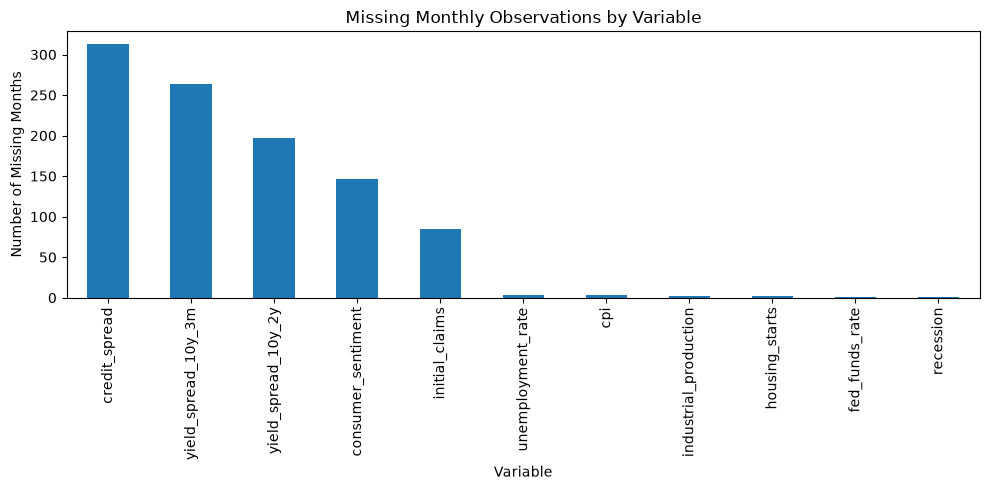

In [19]:
missing.plot(
    kind="bar",
    figsize=(10, 5),
    title="Missing Monthly Observations by Variable"
)

plt.ylabel("Number of Missing Months")
plt.xlabel("Variable")
plt.tight_layout()
plt.show()

In [20]:
df_since_1986 = df_monthly.loc["1986-01-01":]

df_since_1986.isna().sum()

unemployment_rate        3
initial_claims           1
cpi                      3
fed_funds_rate           1
yield_spread_10y_2y      0
yield_spread_10y_3m      0
industrial_production    2
housing_starts           2
consumer_sentiment       2
credit_spread            1
recession                1
dtype: int64

In [21]:
df_since_1986.shape

(490, 11)

## 5. Final Data Selection

Based on the availability of the selected indicators, the analysis is
restricted to observations from January 1986 onwards. This allows the
dataset to retain all selected macroeconomic indicators while avoiding
the large amount of missing data caused by differences in historical
coverage.

Recent months with incomplete observations are removed before further
analysis.

In [22]:
df_clean = df_since_1986.dropna().copy()

df_clean.shape

(487, 11)

In [23]:
df_clean.head()

,unemployment_rate,initial_claims,cpi,fed_funds_rate,yield_spread_10y_2y,yield_spread_10y_3m,industrial_production,housing_starts,consumer_sentiment,credit_spread,recession
1986-01-01,6.7,366750.0,109.9,8.14,1.051429,1.891905,55.7481,1972.0,95.6,2.241429,0.0
1986-02-01,7.2,369500.0,109.7,7.86,0.736842,1.413684,55.3568,1848.0,95.9,2.408421,0.0
1986-03-01,7.2,381200.0,109.1,7.48,0.564000,1.014500,54.9625,1876.0,95.1,2.716500,0.0
1986-04-01,7.1,385750.0,108.7,6.99,0.604091,1.063636,55.0413,1933.0,96.2,2.891364,0.0
1986-05-01,7.2,386000.0,109.0,6.85,0.642381,1.374762,55.1226,1854.0,94.8,2.576190,0.0


In [24]:
df_clean.tail()

,unemployment_rate,initial_claims,cpi,fed_funds_rate,yield_spread_10y_2y,yield_spread_10y_3m,industrial_production,housing_starts,consumer_sentiment,credit_spread,recession
2026-04-01,4.3,207750.0,332.407,3.64,0.520000,0.622727,102.5783,1414.0,49.8,1.711429,0.0
2026-05-01,4.3,211600.0,333.979,3.63,0.489000,0.798500,102.6396,1182.0,44.8,1.619000,0.0
2026-06-01,4.2,222500.0,332.568,3.63,0.357619,0.659524,102.8420,1439.0,49.5,1.530476,0.0
2026-07-01,4.1,203250.0,332.813,3.63,0.376818,0.732727,103.0454,1309.0,55.2,1.585909,0.0
2026-08-01,4.1,206000.0,334.131,3.63,0.468095,0.807619,103.0682,1275.0,51.7,1.631905,0.0


In [25]:
df_clean.isna().sum()

unemployment_rate        0
initial_claims           0
cpi                      0
fed_funds_rate           0
yield_spread_10y_2y      0
yield_spread_10y_3m      0
industrial_production    0
housing_starts           0
consumer_sentiment       0
credit_spread            0
recession                0
dtype: int64

## 6. Save Processed Dataset

The cleaned monthly dataset is saved for use in the exploratory analysis
and modeling stages of the project.

In [26]:
df_clean.to_csv("../data/processed/macroeconomic_monthly.csv")

print("Dataset saved")
print(f"Observations: {len(df_clean)}")
print(f"Period: {df_clean.index.min().date()} to {df_clean.index.max().date()}")

Dataset saved
Observations: 487
Period: 1986-01-01 to 2026-08-01
